# Assignment 4 — Task 2: Spoken Digit Sequential Classification

This notebook trains Vanilla RNN, LSTM, and optional GRU models on the UCI Spoken Arabic Digit dataset.

**Input:** each utterance is a variable-length sequence of 13 MFCC features.  
**Output:** one class label, from digit 0 to digit 9.

## Before running
1. Download `Train_Arabic_Digit.txt` and `Test_Arabic_Digit.txt` from the [UCI Spoken Arabic Digit dataset](https://archive.ics.uci.edu/dataset/195/spoken+arabic+digit).
2. Put both files in a folder named `data` beside this notebook:
   - `data/Train_Arabic_Digit.txt`
   - `data/Test_Arabic_Digit.txt`
3. Run the cells from top to bottom.

The original files contain blank-line-separated utterances. Labels are reconstructed from the documented order: 660 training utterances per digit and 220 test utterances per digit. The loader checks the expected counts so that incorrect parsing does not silently continue.

## 1. Install/import libraries

In [1]:
# If needed, uncomment and run this line in Jupyter:
# %pip install torch numpy pandas matplotlib scikit-learn

import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cpu


## 2. Set paths and load the utterance blocks

In [3]:
import os
from pathlib import Path
import numpy as np

DATA_DIR = Path("/content")
TRAIN_PATH = DATA_DIR / "Train_Arabic_Digit.txt"
TEST_PATH = DATA_DIR / "Test_Arabic_Digit.txt"

# Confirm file existence
print("Train file exists:", TRAIN_PATH.exists())
print("Test file exists:", TEST_PATH.exists())

def read_utterance_blocks(file_path):
    """Read blank-line-separated utterances. Each nonblank line should have 13 numbers."""
    file_path = Path(file_path)
    if not file_path.exists():
        raise FileNotFoundError(
            f"Cannot find {file_path}. Download the UCI text files and put them in the 'data' folder."
        )

    text = file_path.read_text(encoding="utf-8", errors="replace")
    blocks = []
    current_rows = []

    for line in text.splitlines():
        line = line.strip()
        if not line:
            if current_rows:
                blocks.append(np.asarray(current_rows, dtype=np.float32))
                current_rows = []
            continue

        values = line.replace(",", " ").split()
        try:
            row = [float(value) for value in values]
        except ValueError as exc:
            raise ValueError(f"Could not parse numeric row in {file_path}: {line[:100]}") from exc

        if len(row) != 13:
            raise ValueError(
                f"Expected 13 MFCC values per frame, got {len(row)} in line: {line[:100]}"
            )
        current_rows.append(row)

    if current_rows:
        blocks.append(np.asarray(current_rows, dtype=np.float32))

    if not blocks:
        raise ValueError(f"No utterances were read from {file_path}")

    return blocks

train_sequences = read_utterance_blocks(TRAIN_PATH)
test_sequences = read_utterance_blocks(TEST_PATH)

print("Training utterances:", len(train_sequences))
print("Test utterances:", len(test_sequences))
print("First training sequence shape:", train_sequences[0].shape)
print("Number of MFCC features:", train_sequences[0].shape[1])

# According to the UCI documentation, blocks are ordered by digit:
# 660 training utterances per class; 220 test utterances per class.
EXPECTED_TRAIN_PER_CLASS = 660
EXPECTED_TEST_PER_CLASS = 220

if len(train_sequences) != 10 * EXPECTED_TRAIN_PER_CLASS:
    raise ValueError(
        f"Expected 6600 training utterances (660 per digit), found {len(train_sequences)}. "
        "Check that the original UCI text file was downloaded and parsed correctly."
    )

if len(test_sequences) != 10 * EXPECTED_TEST_PER_CLASS:
    raise ValueError(
        f"Expected 2200 test utterances (220 per digit), found {len(test_sequences)}. "
        "Check that the original UCI text file was downloaded and parsed correctly."
    )

y_train_all = np.repeat(np.arange(10), EXPECTED_TRAIN_PER_CLASS).astype(np.int64)
y_test = np.repeat(np.arange(10), EXPECTED_TEST_PER_CLASS).astype(np.int64)

lengths = np.array([len(seq) for seq in train_sequences + test_sequences])
print("Minimum sequence length:", lengths.min())
print("Maximum sequence length:", lengths.max())
print("Training class counts:", np.bincount(y_train_all))
print("Test class counts:", np.bincount(y_test))

Train file exists: True
Test file exists: True
Training utterances: 6600
Test utterances: 2200
First training sequence shape: (38, 13)
Number of MFCC features: 13
Minimum sequence length: 4
Maximum sequence length: 93
Training class counts: [660 660 660 660 660 660 660 660 660 660]
Test class counts: [220 220 220 220 220 220 220 220 220 220]


## 3. Split training data into train and validation sets; standardize MFCCs

In [4]:
all_indices = np.arange(len(train_sequences))
train_idx, val_idx = train_test_split(
    all_indices,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train_all
)

# Calculate feature mean and standard deviation using only the training split.
# Each frame is one observation with 13 MFCC coefficients.
train_frames = np.concatenate([train_sequences[i] for i in train_idx], axis=0)
feature_mean = train_frames.mean(axis=0, keepdims=True)
feature_std = train_frames.std(axis=0, keepdims=True)
feature_std[feature_std < 1e-8] = 1.0

def standardize_sequence_list(sequence_list):
    return [((seq - feature_mean) / feature_std).astype(np.float32) for seq in sequence_list]

train_sequences_scaled = standardize_sequence_list(train_sequences)
test_sequences_scaled = standardize_sequence_list(test_sequences)

X_train = [train_sequences_scaled[i] for i in train_idx]
y_train = y_train_all[train_idx]
X_val = [train_sequences_scaled[i] for i in val_idx]
y_val = y_train_all[val_idx]
X_test = test_sequences_scaled

print("Train split:", len(X_train))
print("Validation split:", len(X_val))
print("Test split:", len(X_test))
print("Feature count:", X_train[0].shape[1])

Train split: 5610
Validation split: 990
Test split: 2200
Feature count: 13


## 4. Dataset and batch collation (padding + sequence lengths)

In [5]:
class MFCCDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = np.asarray(labels, dtype=np.int64)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        return torch.tensor(self.sequences[index], dtype=torch.float32), int(self.labels[index])

def collate_mfcc_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    # Pad only to the longest sequence in this batch.
    padded_sequences = pad_sequence(sequences, batch_first=True, padding_value=0.0)
    labels = torch.tensor(labels, dtype=torch.long)
    return padded_sequences, lengths, labels

BATCH_SIZE = 64

train_dataset = MFCCDataset(X_train, y_train)
val_dataset = MFCCDataset(X_val, y_val)
test_dataset = MFCCDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_mfcc_batch
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_mfcc_batch
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_mfcc_batch
)

# Inspect one batch
batch_x, batch_lengths, batch_y = next(iter(train_loader))
print("Batch input shape (batch, time, MFCC):", batch_x.shape)
print("Sequence lengths in this batch:", batch_lengths[:10].tolist())
print("Labels in this batch:", batch_y[:10].tolist())

Batch input shape (batch, time, MFCC): torch.Size([64, 57, 13])
Sequence lengths in this batch: [30, 38, 39, 38, 37, 38, 33, 39, 40, 37]
Labels in this batch: [0, 5, 0, 5, 5, 7, 9, 5, 3, 0]


## 5. Define Vanilla RNN, LSTM, and GRU classifiers

In [6]:
class RecurrentClassifier(nn.Module):
    def __init__(self, cell_type="RNN", input_size=13, hidden_size=64,
                 num_layers=1, dropout=0.0, num_classes=10, bidirectional=False):
        super().__init__()
        cell_type = cell_type.upper()
        recurrent_dropout = dropout if num_layers > 1 else 0.0

        if cell_type == "RNN":
            self.recurrent = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                nonlinearity="tanh",
                batch_first=True,
                dropout=recurrent_dropout,
                bidirectional=bidirectional
            )
        elif cell_type == "LSTM":
            self.recurrent = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=recurrent_dropout,
                bidirectional=bidirectional
            )
        elif cell_type == "GRU":
            self.recurrent = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=recurrent_dropout,
                bidirectional=bidirectional
            )
        else:
            raise ValueError("cell_type must be 'RNN', 'LSTM', or 'GRU'")

        self.cell_type = cell_type
        self.bidirectional = bidirectional
        directions = 2 if bidirectional else 1
        self.classifier = nn.Linear(hidden_size * directions, num_classes)

    def forward(self, padded_x, lengths):
        # Packing makes the RNN ignore artificial padding frames.
        packed_x = pack_padded_sequence(
            padded_x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.recurrent(packed_x)

        # LSTM returns (hidden_state, cell_state); RNN/GRU return hidden_state.
        if self.cell_type == "LSTM":
            hidden = hidden[0]

        # Shape of hidden: (layers * directions, batch, hidden_size).
        if self.bidirectional:
            # Last layer's forward and backward states.
            final_hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            final_hidden = hidden[-1]

        return self.classifier(final_hidden)

## 6. Training and evaluation functions

In [7]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_examples = 0
    all_true = []
    all_pred = []

    for padded_x, lengths, labels in loader:
        padded_x = padded_x.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(padded_x, lengths)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                # Helps avoid exploding gradients in recurrent networks.
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()

        batch_n = labels.size(0)
        total_loss += loss.item() * batch_n
        total_examples += batch_n
        predictions = logits.argmax(dim=1)

        all_true.extend(labels.detach().cpu().numpy().tolist())
        all_pred.extend(predictions.detach().cpu().numpy().tolist())

    average_loss = total_loss / total_examples
    accuracy = accuracy_score(all_true, all_pred)
    return average_loss, accuracy, np.asarray(all_true), np.asarray(all_pred)


def fit_model(model, train_loader, val_loader, learning_rate=1e-3,
              convergence_threshold=1e-4, max_epochs=200, patience=12):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}
    previous_train_loss = None
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    stop_reason = "maximum epochs reached"

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc, _, _ = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, _, _ = run_epoch(model, val_loader, criterion, optimizer=None)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch:03d} | train loss={train_loss:.6f} | "
            f"val loss={val_loss:.6f} | train acc={train_acc:.4f} | val acc={val_acc:.4f}"
        )

        # Assignment stopping rule: change in average training loss < 1e-4.
        # Compare consecutive epoch losses, not a fixed epoch count.
        if previous_train_loss is not None:
            loss_change = abs(train_loss - previous_train_loss)
            if loss_change < convergence_threshold:
                stop_reason = (
                    f"convergence rule met: |loss change|={loss_change:.6g} "
                    f"< {convergence_threshold}"
                )
                print("Stopping:", stop_reason)
                break

        # Practical safety cap if validation loss stops improving for a long time.
        # The convergence rule remains the primary requested stopping criterion.
        if epochs_without_improvement >= patience:
            stop_reason = f"early stop: validation loss did not improve for {patience} epochs"
            print("Stopping:", stop_reason)
            break

        previous_train_loss = train_loss

    model.load_state_dict(best_state)
    history["stop_reason"] = stop_reason
    return model, history


def evaluate_model(model, loader):
    criterion = nn.CrossEntropyLoss()
    loss, acc, y_true, y_pred = run_epoch(model, loader, criterion, optimizer=None)
    return {"loss": loss, "accuracy": acc, "y_true": y_true, "y_pred": y_pred}

## 7. Run hyperparameter experiments

In [8]:
# Keep the first run small while checking that the pipeline works.
# For your final report, try more configurations and compare their curves.
CONFIGS = [
    {"cell": "RNN",  "hidden_size": 64,  "num_layers": 1, "dropout": 0.0, "lr": 1e-3},
    {"cell": "RNN",  "hidden_size": 128, "num_layers": 2, "dropout": 0.2, "lr": 1e-3},
    {"cell": "LSTM", "hidden_size": 64,  "num_layers": 1, "dropout": 0.0, "lr": 1e-3},
    {"cell": "LSTM", "hidden_size": 128, "num_layers": 2, "dropout": 0.2, "lr": 1e-3},
    {"cell": "GRU",  "hidden_size": 64,  "num_layers": 1, "dropout": 0.0, "lr": 1e-3},  # bonus
]

results = []
trained_models = {}
histories = {}

for run_number, config in enumerate(CONFIGS, start=1):
    run_name = (
        f"{config['cell']}_h{config['hidden_size']}_layers{config['num_layers']}"
    )
    print("\n" + "=" * 80)
    print(f"Experiment {run_number}/{len(CONFIGS)}: {run_name}")
    print("=" * 80)

    model = RecurrentClassifier(
        cell_type=config["cell"],
        input_size=13,
        hidden_size=config["hidden_size"],
        num_layers=config["num_layers"],
        dropout=config["dropout"],
        num_classes=10
    ).to(DEVICE)

    model, history = fit_model(
        model,
        train_loader,
        val_loader,
        learning_rate=config["lr"],
        convergence_threshold=1e-4,
        max_epochs=200,
        patience=12
    )

    train_metrics = evaluate_model(model, train_loader)
    val_metrics = evaluate_model(model, val_loader)
    test_metrics = evaluate_model(model, test_loader)

    trained_models[run_name] = model
    histories[run_name] = history

    results.append({
        "model": run_name,
        "cell": config["cell"],
        "hidden_size": config["hidden_size"],
        "layers": config["num_layers"],
        "epochs": len(history["train_loss"]),
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "validation_accuracy": val_metrics["accuracy"],
        "test_loss": test_metrics["loss"],
        "test_accuracy": test_metrics["accuracy"],
        "stopping_reason": history["stop_reason"]
    })

results_df = pd.DataFrame(results).sort_values("validation_accuracy", ascending=False)
display(results_df)



Experiment 1/5: RNN_h64_layers1
Epoch 001 | train loss=1.832552 | val loss=1.463994 | train acc=0.3294 | val acc=0.4515
Epoch 002 | train loss=1.299047 | val loss=1.196285 | train acc=0.5189 | val acc=0.5364
Epoch 003 | train loss=1.132332 | val loss=1.091788 | train acc=0.5677 | val acc=0.5707
Epoch 004 | train loss=1.041077 | val loss=1.002333 | train acc=0.6000 | val acc=0.6051
Epoch 005 | train loss=0.937362 | val loss=0.922282 | train acc=0.6367 | val acc=0.6424
Epoch 006 | train loss=0.829879 | val loss=0.769794 | train acc=0.6854 | val acc=0.7101
Epoch 007 | train loss=0.732045 | val loss=0.866126 | train acc=0.7193 | val acc=0.6848
Epoch 008 | train loss=0.674092 | val loss=0.660198 | train acc=0.7376 | val acc=0.7374
Epoch 009 | train loss=0.650697 | val loss=0.604803 | train acc=0.7444 | val acc=0.7636
Epoch 010 | train loss=0.608383 | val loss=0.649358 | train acc=0.7528 | val acc=0.7515
Epoch 011 | train loss=0.568504 | val loss=0.595864 | train acc=0.7729 | val acc=0.7697

,model,cell,hidden_size,layers,epochs,train_loss,train_accuracy,validation_accuracy,test_loss,test_accuracy,stopping_reason
4,GRU_h64_layers1,GRU,64,1,31,0.003689,0.999643,0.993939,0.178531,0.960455,convergence rule met: |loss change|=3.88723e-0...
3,LSTM_h128_layers2,LSTM,128,2,23,0.001029,0.999822,0.992929,0.119720,0.972727,convergence rule met: |loss change|=8.49001e-0...
2,LSTM_h64_layers1,LSTM,64,1,33,0.011384,0.998039,0.987879,0.231952,0.948182,early stop: validation loss did not improve fo...
1,RNN_h128_layers2,RNN,128,2,35,0.093317,0.973797,0.964646,0.344511,0.919091,early stop: validation loss did not improve fo...
0,RNN_h64_layers1,RNN,64,1,51,0.076760,0.981283,0.963636,0.508800,0.888636,early stop: validation loss did not improve fo...


## 8. Plot average training loss versus epochs for every configuration

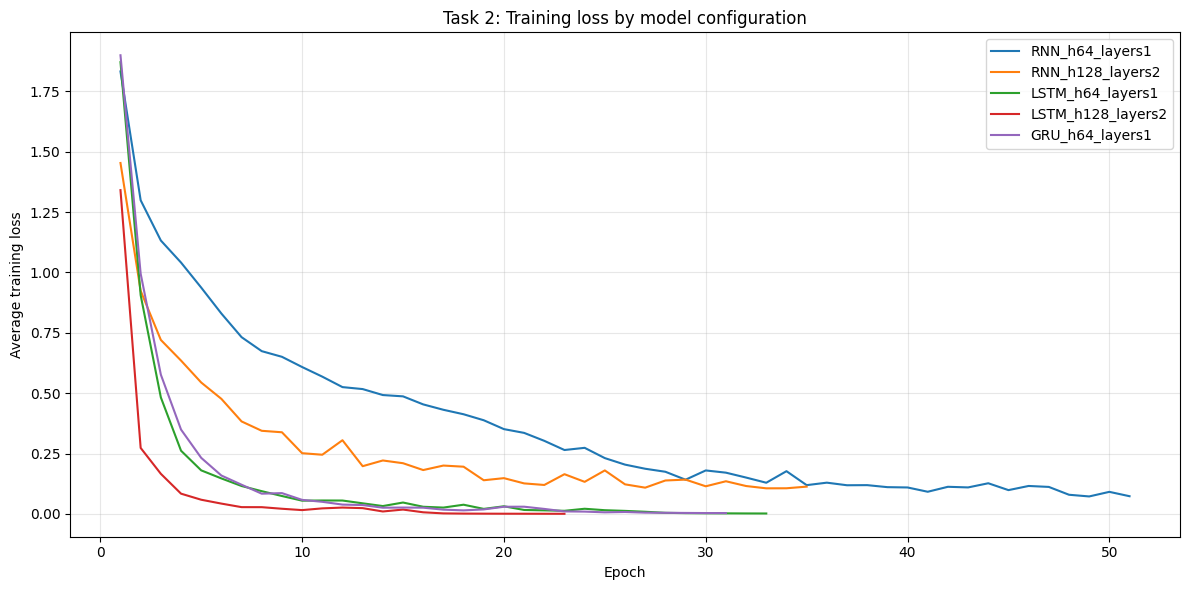

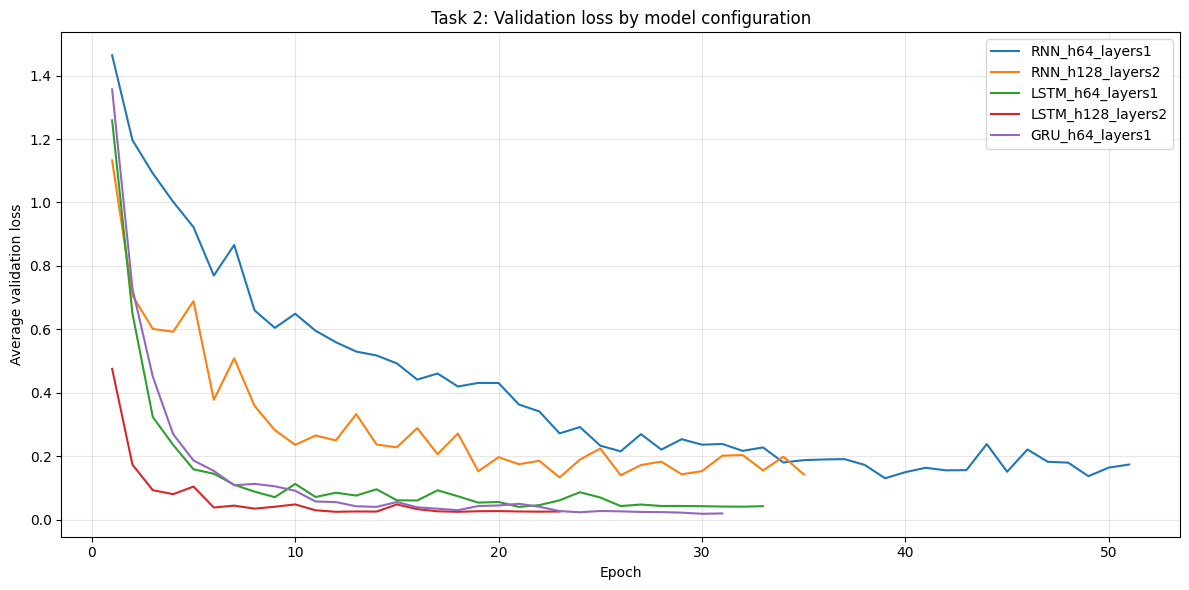

In [9]:
plt.figure(figsize=(12, 6))
for name, history in histories.items():
    plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Task 2: Training loss by model configuration")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Optional validation-loss plot
plt.figure(figsize=(12, 6))
for name, history in histories.items():
    plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Average validation loss")
plt.title("Task 2: Validation loss by model configuration")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

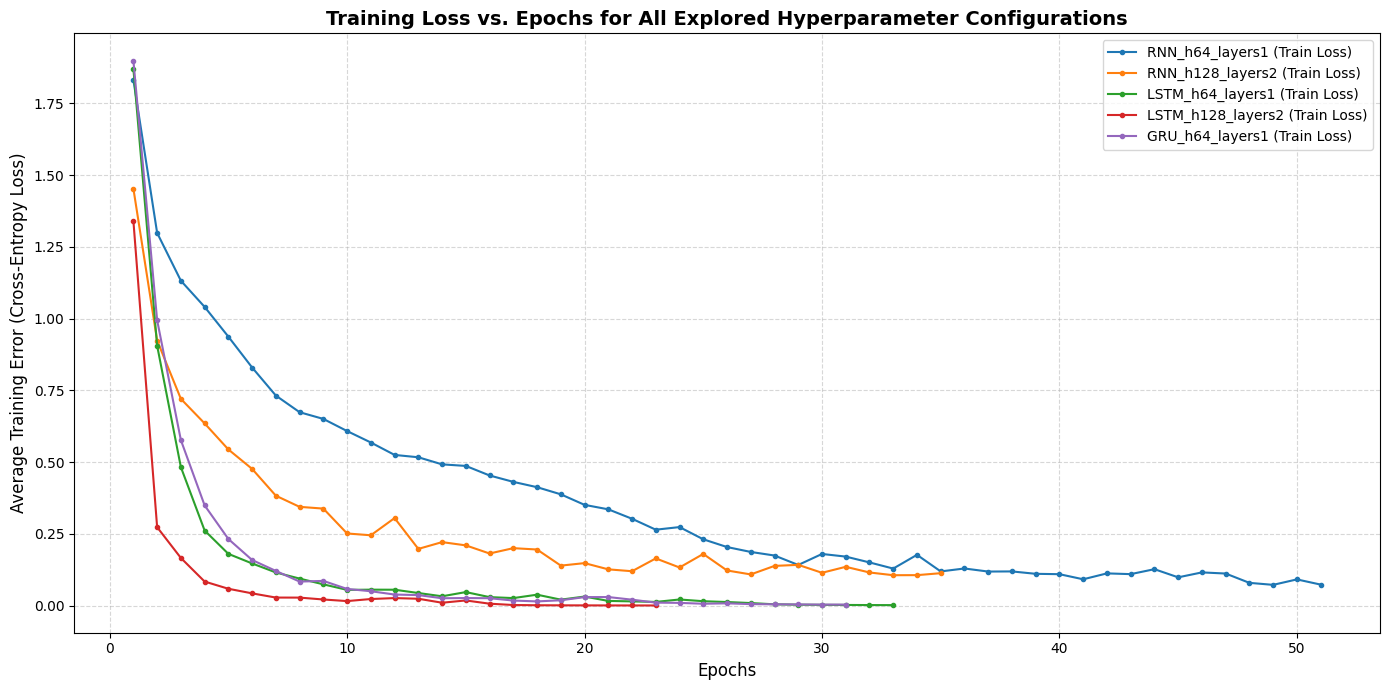

In [10]:
import matplotlib.pyplot as plt

# Set style for academic/technical reporting
plt.figure(figsize=(14, 7))

# Loop over each trained model history to plot its training loss curve
for model_name, history in histories.items():
    epochs = range(1, len(history["train_loss"]) + 1)
    plt.plot(epochs, history["train_loss"], marker='o', markersize=3, label=f"{model_name} (Train Loss)")

plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Average Training Error (Cross-Entropy Loss)", fontsize=12)
plt.title("Training Loss vs. Epochs for All Explored Hyperparameter Configurations", fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()

## 9. Best model: test accuracy, classification report, and confusion matrix

Best model selected by validation accuracy: GRU_h64_layers1
Test loss: 0.1785
Test accuracy: 0.9605

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.97      0.93       220
           1       0.95      1.00      0.97       220
           2       0.94      0.99      0.96       220
           3       0.97      0.92      0.94       220
           4       0.99      0.96      0.97       220
           5       0.98      0.98      0.98       220
           6       0.98      0.85      0.91       220
           7       0.95      0.95      0.95       220
           8       0.97      0.99      0.98       220
           9       0.99      1.00      0.99       220

    accuracy                           0.96      2200
   macro avg       0.96      0.96      0.96      2200
weighted avg       0.96      0.96      0.96      2200



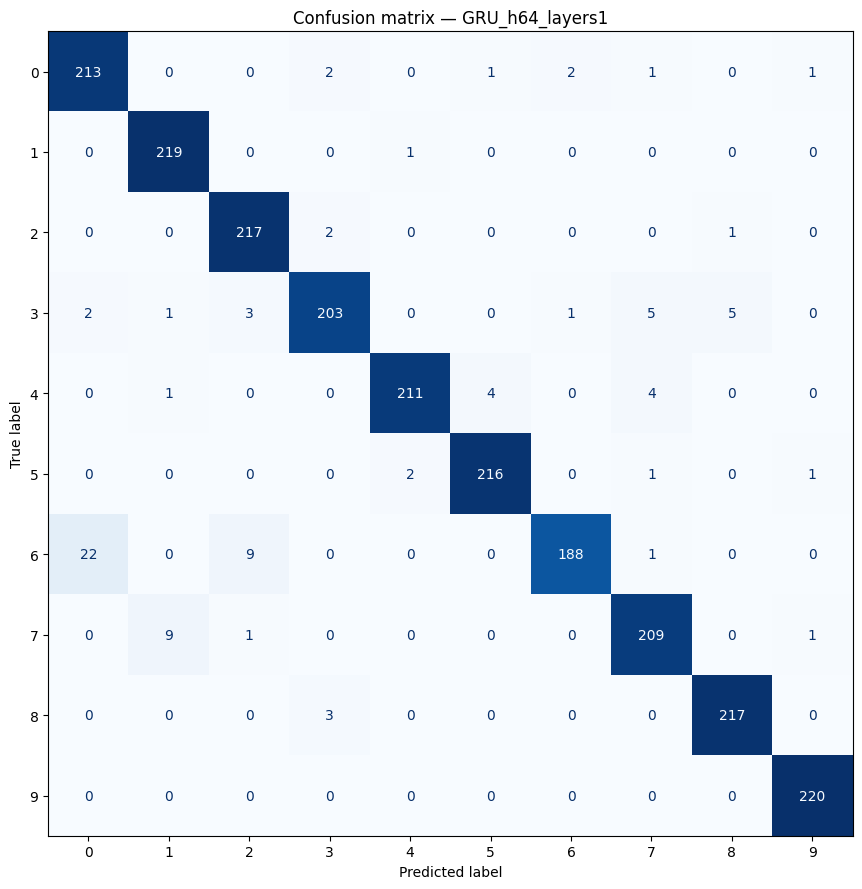

In [11]:
best_model_name = results_df.iloc[0]["model"]
best_model = trained_models[best_model_name]
best_test = evaluate_model(best_model, test_loader)

print("Best model selected by validation accuracy:", best_model_name)
print(f"Test loss: {best_test['loss']:.4f}")
print(f"Test accuracy: {best_test['accuracy']:.4f}")
print("\nClassification report:")
print(classification_report(
    best_test["y_true"],
    best_test["y_pred"],
    labels=list(range(10)),
    zero_division=0
))

cm = confusion_matrix(best_test["y_true"], best_test["y_pred"], labels=list(range(10)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title(f"Confusion matrix — {best_model_name}")
plt.tight_layout()
plt.show()

Best RNN Architecture: RNN_h128_layers2
Best LSTM Architecture: LSTM_h128_layers2


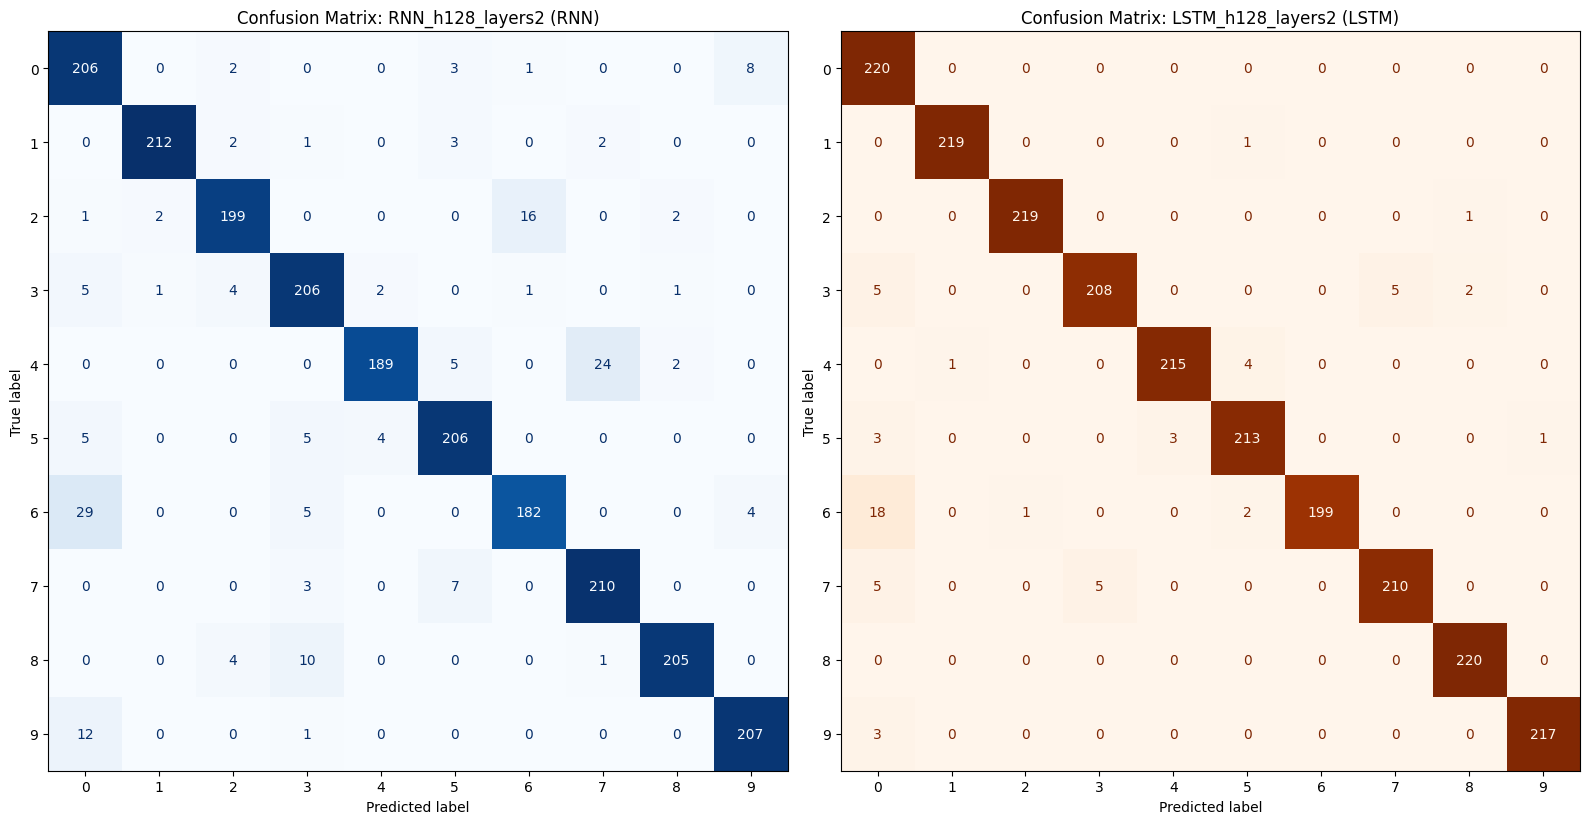

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Filter results to find the best RNN and LSTM models
rnn_results = results_df[results_df['cell'] == 'RNN']
lstm_results = results_df[results_df['cell'] == 'LSTM']

best_rnn_name = rnn_results.iloc[0]['model'] if not rnn_results.empty else None
best_lstm_name = lstm_results.iloc[0]['model'] if not lstm_results.empty else None

print(f"Best RNN Architecture: {best_rnn_name}")
print(f"Best LSTM Architecture: {best_lstm_name}")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# 1. Plot Best RNN Confusion Matrix
if best_rnn_name and best_rnn_name in trained_models:
    rnn_model = trained_models[best_rnn_name]
    rnn_eval = evaluate_model(rnn_model, test_loader)
    cm_rnn = confusion_matrix(rnn_eval['y_true'], rnn_eval['y_pred'], labels=list(range(10)))
    disp_rnn = ConfusionMatrixDisplay(confusion_matrix=cm_rnn, display_labels=list(range(10)))
    disp_rnn.plot(ax=axes[0], cmap='Blues', values_format='d', colorbar=False)
    axes[0].set_title(f"Confusion Matrix: {best_rnn_name} (RNN)")
else:
    axes[0].text(0.5, 0.5, 'RNN model not found', ha='center', va='center')

# 2. Plot Best LSTM Confusion Matrix
if best_lstm_name and best_lstm_name in trained_models:
    lstm_model = trained_models[best_lstm_name]
    lstm_eval = evaluate_model(lstm_model, test_loader)
    cm_lstm = confusion_matrix(lstm_eval['y_true'], lstm_eval['y_pred'], labels=list(range(10)))
    disp_lstm = ConfusionMatrixDisplay(confusion_matrix=cm_lstm, display_labels=list(range(10)))
    disp_lstm.plot(ax=axes[1], cmap='Oranges', values_format='d', colorbar=False)
    axes[1].set_title(f"Confusion Matrix: {best_lstm_name} (LSTM)")
else:
    axes[1].text(0.5, 0.5, 'LSTM model not found', ha='center', va='center')

plt.tight_layout()
plt.show()

## 10. Visualize MFCC heatmaps for representative utterances

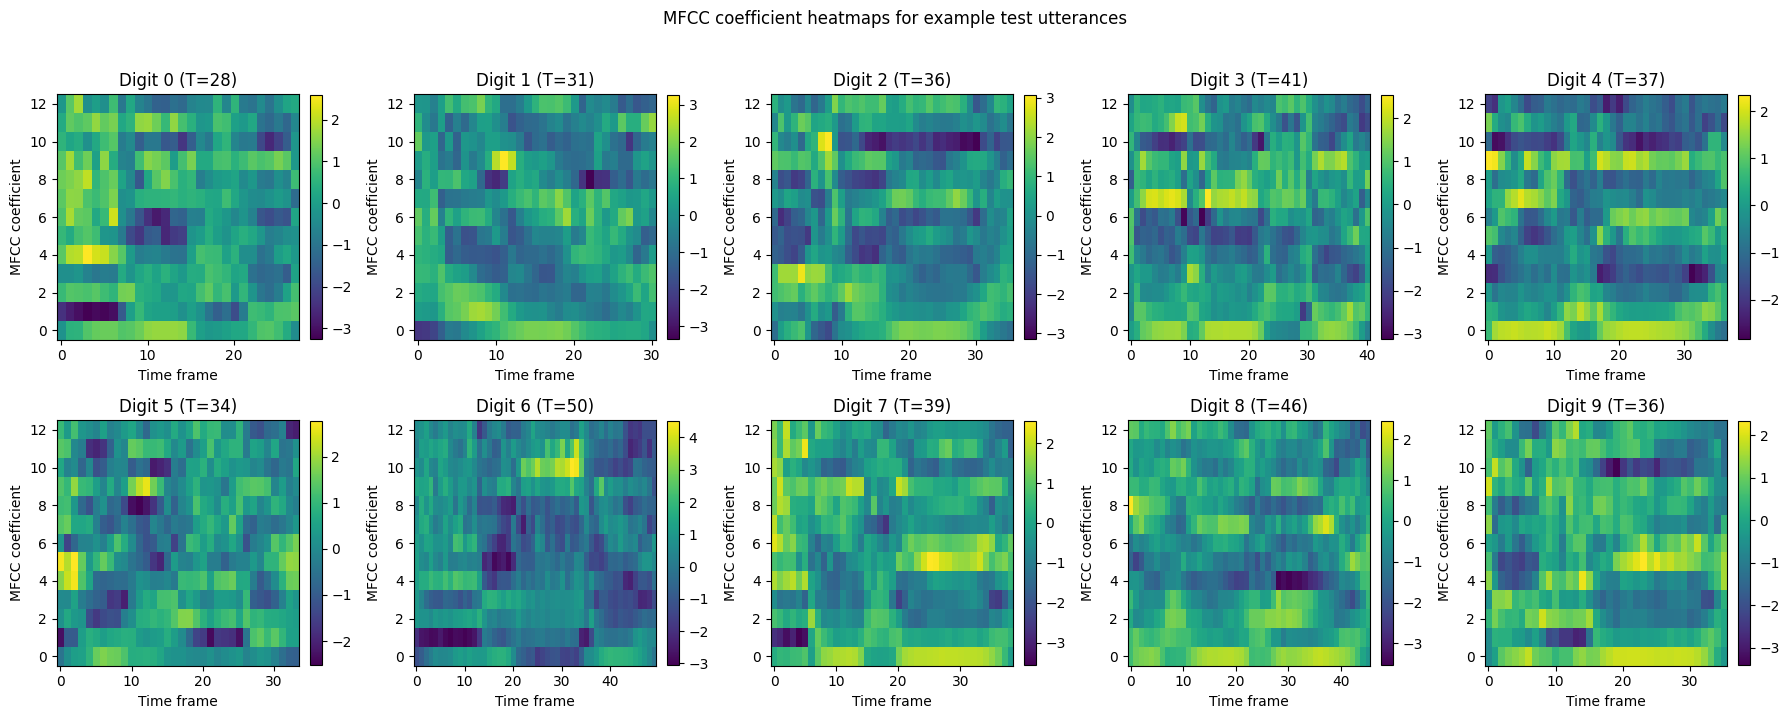

In [13]:
def plot_mfcc_heatmaps(sequences, labels, digits_to_show=range(10)):
    fig, axes = plt.subplots(2, 5, figsize=(18, 7))
    axes = axes.ravel()

    for ax, digit in zip(axes, digits_to_show):
        indices = np.where(np.asarray(labels) == digit)[0]
        if len(indices) == 0:
            ax.set_title(f"Digit {digit}: no sample")
            ax.axis("off")
            continue

        seq = sequences[int(indices[0])]
        image = ax.imshow(seq.T, aspect="auto", origin="lower", interpolation="nearest")
        ax.set_title(f"Digit {digit} (T={len(seq)})")
        ax.set_xlabel("Time frame")
        ax.set_ylabel("MFCC coefficient")
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

    plt.suptitle("MFCC coefficient heatmaps for example test utterances", y=1.02)
    plt.tight_layout()
    plt.show()

plot_mfcc_heatmaps(X_test, y_test)

## 11. Save the experiment table

In [14]:
results_df.to_csv("task2_results.csv", index=False)
print("Saved results to task2_results.csv")

Saved results to task2_results.csv


In [15]:
# Pipeline Cleanup
# This duplicate experiment execution cell has been cleaned up to prevent name definition conflicts.
# Please run the original step-by-step cells (from Section 3 to Section 11) in sequential order from top to bottom.

## 12. Notes for the report

- **RNN vs LSTM:** compare their training-loss curves, validation accuracy, test accuracy, and confusion matrices. LSTM has gates that can help preserve information over longer sequences; a vanilla RNN can have more difficulty learning long-range dependencies.
- **GRU:** an optional bonus model. It also uses gates but has a simpler structure than LSTM.
- **Padding:** batches need a common time dimension. `pad_sequence` adds zeros to shorter utterances within a batch.
- **Packing:** `pack_padded_sequence` tells the recurrent layer the true length of each utterance, so padded frames are not treated as real speech frames.
- **Convergence:** the requested condition is `abs(current_training_loss - previous_training_loss) < 1e-4`. The notebook also has a validation-based patience safety stop and a maximum epoch cap; mention these clearly in your report if either safety condition ends a run.
- **Speaker split:** the UCI documentation states the test speakers are different from the training speakers, so the supplied test file is kept separate from training and validation.
- **Reproducibility:** report the configurations you actually ran and the results produced by your notebook. Do not invent or copy example accuracies.